# Tendência própria: *harness* de *backtest* para a Coleta de 90 dias (fase 2b)

**Ficha:** [`docs/modelagens/tendencia.md`](../../docs/modelagens/tendencia.md) · **ADR:** 0040 (proposto) · **Status:** em avaliação
· **Fases anteriores:** [`tendencia_01_simulacao.ipynb`](tendencia_01_simulacao.ipynb),
[`tendencia_02_proporcoes_e_agregacao.ipynb`](tendencia_02_proporcoes_e_agregacao.ipynb) · **Issue:** #284 (spec #280)

## 1. O que este notebook é (e o que não é)

O #284 pede um *backtest* de origem móvel **com dado real da Coleta de 90 dias** (#256), que ainda **não existe**. Este notebook
entrega o **instrumento pronto**: carrega as séries brutas de uma Coleta, roda o *backtest*, mede estabilidade da classificação,
cobertura, distribuição de estados e sensibilidade aos limiares, e confere as premissas do gerador contra o dado.

- **Não decide** método nem limiares finais, **não fecha** o #284 e **não altera** ADR, ficha ou `CONTEXT.md`.
- **Validação do instrumento sem a Coleta:** (a) *backtest* sobre dados sintéticos do gerador do notebook 02, onde a verdade é
  conhecida, com asserções de sanidade; (b) teste de fumaça sobre a Silver do piloto, que **só mostra que o código roda**.
- Quando a Coleta existir, troque **um** parâmetro (`COLETA_DIR`, seção 2) e execute de ponta a ponta. O passo a passo está na
  última seção.
- Leitura **somente-leitura** do disco: nenhuma extração, nenhum custo, nenhuma escrita em `data/`.

## 2. Contrato dos quatro estados (igual ao das fases 1 e 2a; parâmetros a calibrar)

- **Dados insuficientes**: menos de `MIN_PUBLICACOES` publicações ou de `MIN_DIAS_COM_PUBLICACAO` dias distintos na janela.
- **Subindo / Caindo**: o IC de 95% da variação na janela exclui zero **e** a variação estimada passa de `MIN_EFEITO`.
- **Estável**: todo o resto (no produto: "sem evidência suficiente de mudança").

Métodos avaliados (os finalistas das fases 1 e 2a, sem novidade): **contagem** = OLS de `log(valor)` no tempo com o formato do
conteúdo como controle; **proporção** = OLS de `log((k+0,5)/(n+1))` por publicação, com formato como controle; **visão "Todos"** =
mediana das tendências individuais (cada perfil pesa igual), IC por *bootstrap* de perfis.

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from scipy.special import expit, logit

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
T0 = time.time()

# ===== PARÂMETRO ÚNICO A TROCAR QUANDO A COLETA DE 90 DIAS EXISTIR ===================================================
# Pasta que contém `silver/` e `gold/` da Coleta (Delta). Default: a Silver/Gold local do PILOTO (somente leitura).
COLETA_DIR = r"C:\Projetos\Tecnicas-de-NLP-em-dados-do-Instagram\data"
# =====================================================================================================================

# Recorte e janelas do backtest (dias). Com a Coleta de 90 dias: janelas de 30 dias, origem andando de 15 em 15.
RECORTE_DIAS = 90          # usa os últimos N dias de publicação da Coleta (None = todo o histórico carregado)
JANELA_DIAS = 30           # tamanho de cada janela (estima numa, avalia na seguinte)
PASSO_DIAS = 15            # deslocamento da origem móvel

# Contrato (pontos de partida; faixas sugeridas no #287 / ADR 0040)
MIN_PUBLICACOES = 10
MIN_DIAS_COM_PUBLICACAO = 8
MIN_EFEITO = 0.05
NIVEL_CONF = 0.95
GRADE_MIN_EFEITO = [0.02, 0.05, 0.10]
GRADE_MINIMOS = [(10, 8), (15, 12), (20, 15)]   # (publicações, dias distintos)

# Simulação (dimensionada para ~10 min no total)
PERIODO_DIAS = 90
N_GOVERNADORES = 26
SEED = 20261013
REPS_BT = 140
N_PUBS = [60, 150, 250]       # publicações por perfil nos 90 dias
EFEITOS = np.array([-0.30, -0.15, 0.0, 0.15, 0.30])
PROBS = np.array([0.10, 0.15, 0.50, 0.15, 0.10])
# cenários de efeito (variação verdadeira em 90 dias). "forte" é irreal de propósito: serve para testar o instrumento.
EF_FORTE = (-0.78, 0.0, 3.48)   # log(1+e)/3 = -0,5 / 0 / +0,5 por janela de 30 dias

## 3. Métodos e contrato (reproduzidos das fases 1 e 2a, autocontido)

A variação estimada é a **inclinação por janela**: o tempo de cada janela vai de 0 a 1, então `exp(inclinação) - 1` é a variação
relativa dentro da janela. (No produto, a janela é o período inteiro; aqui ela é uma fração dele, o que reduz o poder.)

In [2]:
_T = {}


def tcrit(gl):
    gl = max(int(gl), 1)
    if gl not in _T:
        _T[gl] = stats.t.ppf(0.5 + NIVEL_CONF / 2, gl)
    return _T[gl]


Z = stats.norm.ppf(0.5 + NIVEL_CONF / 2)


def ols(y, X):
    inv = np.linalg.inv(X.T @ X)
    beta = inv @ X.T @ y
    res = y - X @ beta
    gl = len(y) - X.shape[1]
    s2 = float(res @ res / gl)
    return beta, s2 * inv, gl, s2, res


def montar_X(t, formato, usa_formato):
    cols = [np.ones(len(t)), t]
    if usa_formato:
        cols.append(formato)
    return np.column_stack(cols)


def resposta(df, tipo):
    """Resposta do OLS: log do valor (contagem) ou log((k+0,5)/(n+1)) (proporção)."""
    if tipo == "contagem":
        return np.log(df["y"].to_numpy(float))
    return np.log((df["k"].to_numpy(float) + 0.5) / (df["n"].to_numpy(float) + 1.0))


def preparar(df, tipo):
    """Série de um perfil -> arrays ordenados por dia (dia, formato, z)."""
    d = df.sort_values("dia", kind="stable")
    return {"dia": d["dia"].to_numpy(float), "fmt": d["formato"].to_numpy(float), "z": resposta(d, tipo)}


def classificar(d, min_pub=None, min_dias=None, min_efeito=None):
    """Aplica o contrato dos quatro estados a colunas npub, ndias, est, lo, hi (escala log)."""
    min_pub = MIN_PUBLICACOES if min_pub is None else min_pub
    min_dias = MIN_DIAS_COM_PUBLICACAO if min_dias is None else min_dias
    min_efeito = MIN_EFEITO if min_efeito is None else min_efeito
    insuf = (d["npub"] < min_pub) | (d["ndias"] < min_dias) | d["est"].isna()
    est, lo, hi = np.expm1(d["est"]), np.expm1(d["lo"]), np.expm1(d["hi"])
    sobe = (lo > 0) & (est >= min_efeito)
    cai = (hi < 0) & (est <= -min_efeito)
    return pd.Series(
        np.where(insuf, "Dados insuficientes", np.where(sobe, "Subindo", np.where(cai, "Caindo", "Estável"))), index=d.index
    )


def mediana_boot(b, rng, B=300):
    """Mediana das tendências individuais com IC por bootstrap de perfis."""
    b = np.asarray(b, float)
    idx = rng.integers(0, len(b), size=(B, len(b)))
    meds = np.median(b[idx], axis=1)
    lo, hi = np.quantile(meds, [(1 - NIVEL_CONF) / 2, 1 - (1 - NIVEL_CONF) / 2])
    return float(np.median(b)), float(lo), float(hi)

## 4. Gerador de séries sintéticas (copiado do notebook 02)

Contagem: `valor = nível * (1 + efeito)^t * ruído log-normal`, com cenários `base`, `viral` (4% de posts ×8) e `mix` (mudança de
participação entre formatos sem efeito real). Proporção: `n` comentários log-normal por publicação, `k` positivos com proporção
que muda linearmente no logit; cenários `base`, `viral`, `mix` e `poucos` (poucos comentários por post). Publicação irregular:
os dias são sorteados com pesos gama (rajadas e buracos). `curva` permite uma tendência **não linear** (campanha), usada só para
mostrar o que o instrumento enxerga quando a premissa de linearidade falha.

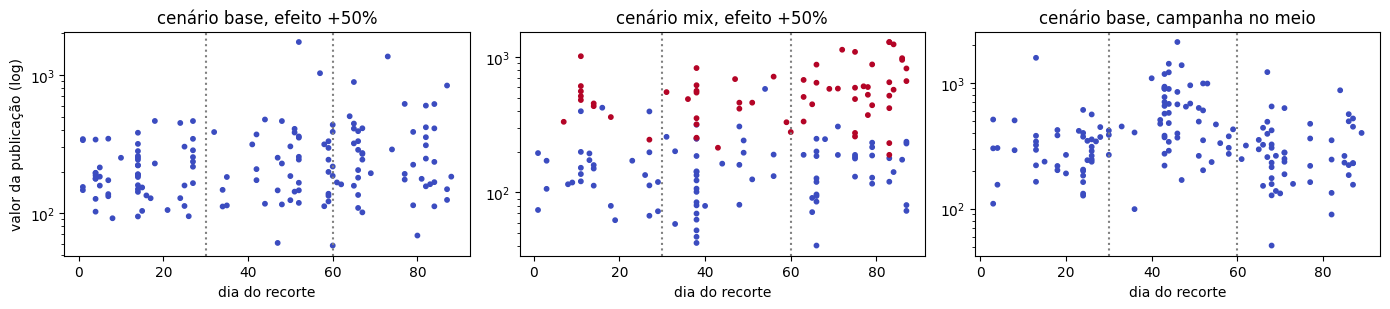

In [3]:
def _dias_irregulares(rng, n):
    pesos = rng.gamma(0.6, size=PERIODO_DIAS)
    return np.sort(rng.choice(PERIODO_DIAS, size=n, p=pesos / pesos.sum()))


def gerar_perfil(rng, n, efeito, cenario, curva=None):
    dias = _dias_irregulares(rng, n)
    t = dias / PERIODO_DIAS
    sigma, p_viral, mult_viral = 0.5, 0.01, 5
    if cenario == "viral":
        sigma, p_viral, mult_viral = 0.6, 0.04, 8
    if cenario == "puro":  # só para o diagnóstico: log-normal pura, sem posts virais
        p_viral = 0.0
    nivel = rng.lognormal(mean=np.log(200), sigma=0.8)
    formato = np.zeros(n, dtype=int)
    if cenario == "mix":
        formato = (rng.random(n) < 0.2 + 0.4 * t).astype(int)
    tendencia = np.log1p(efeito) * t if curva is None else curva(t)
    log_y = (
        np.log(nivel) + tendencia + 1.1 * formato + rng.normal(0, sigma, n) + (rng.random(n) < p_viral) * np.log(mult_viral)
    )
    return pd.DataFrame({"dia": dias, "t": t, "formato": formato, "y": np.exp(log_y)})


def gerar_perfil_prop(rng, n, efeito, cenario):
    dias = _dias_irregulares(rng, n)
    t = dias / PERIODO_DIAS
    sigma, p_viral = 0.4, 0.01
    if cenario == "viral":
        sigma, p_viral = 0.5, 0.04
    mult_com = 0.15 if cenario == "poucos" else 1.0
    # teto de p0 garante p0*(1+efeito) < 0,9 também nos efeitos grandes do cenário 'forte' (idêntico ao notebook 02 até +50%)
    p0 = float(np.clip(rng.beta(4, 8), 0.03, min(0.6, 0.9 / (1 + max(efeito, 0.0)))))
    a0 = logit(p0)
    inclinacao = logit(p0 * (1 + efeito)) - a0
    escala = rng.lognormal(np.log(40), 0.7) * mult_com
    n_com = np.maximum(1, np.round(rng.lognormal(np.log(escala), 0.9, n))).astype(int)
    viral = rng.random(n) < p_viral
    n_com = np.where(viral, n_com * 15, n_com)
    desloc = np.where(viral, rng.choice([-1.2, 1.2], n), 0.0)
    formato = np.zeros(n, dtype=int)
    if cenario == "mix":
        formato = (rng.random(n) < 0.2 + 0.4 * t).astype(int)
    p = expit(a0 + inclinacao * t + 0.8 * formato + rng.normal(0, sigma, n) + desloc)
    k = rng.binomial(n_com, p)
    return pd.DataFrame({"dia": dias, "t": t, "formato": formato, "n": n_com, "k": k})


def campanha_meio(t):
    """Tendência não linear: pico de campanha centrado no dia 45 (largura ~11 dias), +0,8 em log, variação ponta a ponta ~0."""
    return 0.8 * np.exp(-0.5 * ((t - 0.5) / 0.12) ** 2)


rng_demo = np.random.default_rng(SEED)
fig, eixos = plt.subplots(1, 3, figsize=(14, 3.2))
for ax, (cen, cur) in zip(eixos, [("base", None), ("mix", None), ("base", campanha_meio)]):
    d = gerar_perfil(rng_demo, 150, 0.0 if cur else 0.5, cen, cur)
    ax.scatter(d["dia"], d["y"], s=10, c=d["formato"], cmap="coolwarm")
    ax.set_yscale("log")
    ax.set_title(f"cenário {cen}" + (", campanha no meio" if cur else ", efeito +50%"))
    ax.set_xlabel("dia do recorte")
    for x in (30, 60):
        ax.axvline(x, color="gray", ls=":")
eixos[0].set_ylabel("valor da publicação (log)")
plt.tight_layout()
plt.show()

## 5. O *backtest* de origem móvel

Para cada governador e cada **origem** `s` (0, 15, 30, ... dias), o instrumento:

1. estima a Tendência na janela de **treino** `[s, s+W)`;
2. estima a Tendência, de forma independente, na janela **seguinte** `[s+W, s+2W)` (a "seta de amanhã");
3. **prevê** a janela seguinte com o ajuste do treino e mede o erro (sem olhar o futuro: o ajuste usa só dados do treino; há uma
   asserção contra vazamento temporal).

Métricas (todas recalculáveis para qualquer combinação de limiares, porque a tabela guarda as estimativas brutas):

- **persistência**: dado que a seta do treino é Subindo/Caindo, a mesma seta se repete na janela seguinte? **Inversão**: aparece
  a seta oposta? **Concordância**: entre janelas ambas classificadas, o estado é o mesmo?
- **cobertura da previsão**: fração em que a média (em log) da janela seguinte cai dentro do intervalo de previsão da média
  (nominal 95%); e, por publicação, fração dos pontos dentro do intervalo de previsão individual (sensível ao ruído log-normal).
- **ganho de previsão**: `1 - EQM(com tendência) / EQM(só nível)`, comparando a extrapolação da reta com repetir a média do treino.
  Valor negativo = extrapolar a tendência piora a previsão.
- **distribuição de estados** na janela mais recente e **sensibilidade** a `MIN_EFEITO` e aos mínimos.
- Só no sintético (verdade conhecida): **falso alarme**, **poder**, **direção errada** e **cobertura do IC da variação**.

In [4]:
def ajustar(dia, fmt, z, ini, W):
    """OLS de uma janela. Devolve (resumo, ajuste). t = (dia - ini)/W, então a inclinação é a variação (log) na janela."""
    out = {"npub": len(z), "ndias": int(np.unique(dia).size), "est": np.nan, "lo": np.nan, "hi": np.nan}
    if len(z) < 5 or out["ndias"] < 3:
        return out, None
    t = (dia - ini) / W
    usa = np.unique(fmt).size > 1
    X = montar_X(t, fmt, usa)
    if len(z) - X.shape[1] < 1 or np.linalg.cond(X) > 1e8:
        return out, None
    beta, cov, gl, s2, _ = ols(z, X)
    se = float(np.sqrt(cov[1, 1]))
    c = tcrit(gl)
    out.update(est=float(beta[1]), lo=float(beta[1] - c * se), hi=float(beta[1] + c * se))
    return out, {"beta": beta, "cov": cov, "gl": gl, "s2": s2, "usa": usa, "ini": ini, "W": W, "media_treino": float(z.mean())}


def prever(aj, dia, fmt, z):
    """Previsão da janela seguinte com o ajuste do treino: erro da média e cobertura dos intervalos de previsão."""
    nan = {"cov_media": np.nan, "cov_post": np.nan, "mse_modelo": np.nan, "mse_ingenuo": np.nan}
    if aj is None or len(z) < 3:
        return nan
    X = montar_X((dia - aj["ini"]) / aj["W"], fmt, aj["usa"])
    pred = X @ aj["beta"]
    c = tcrit(aj["gl"])
    xbar = X.mean(axis=0)
    var_media = aj["s2"] / len(z) + xbar @ aj["cov"] @ xbar
    erro_media = z.mean() - xbar @ aj["beta"]
    var_post = aj["s2"] + np.einsum("ij,jk,ik->i", X, aj["cov"], X)
    return {
        "cov_media": float(abs(erro_media) <= c * np.sqrt(var_media)),
        "cov_post": float(np.mean(np.abs(z - pred) <= c * np.sqrt(var_post))),
        "mse_modelo": float(erro_media**2),
        "mse_ingenuo": float((z.mean() - aj["media_treino"]) ** 2),
    }


def backtest_perfil(S, total, W=None, passo=None):
    """Origem móvel em um perfil. S = preparar(df). Linhas com sufixos _tr (treino) e _te (janela seguinte)."""
    W = JANELA_DIAS if W is None else W
    passo = PASSO_DIAS if passo is None else passo
    dia, fmt, z = S["dia"], S["fmt"], S["z"]
    linhas, s = [], 0
    while s + 2 * W <= total:
        a, b = np.searchsorted(dia, [s, s + W]), np.searchsorted(dia, [s + W, s + 2 * W])
        itr, ite = slice(a[0], a[1]), slice(b[0], b[1])
        if a[1] > a[0] and b[1] > b[0]:
            assert dia[itr].max() < dia[ite].min(), "vazamento temporal: treino alcança a janela seguinte"
        r_tr, aj = ajustar(dia[itr], fmt[itr], z[itr], s, W)
        r_te, _ = ajustar(dia[ite], fmt[ite], z[ite], s + W, W)
        linha = {"origem": s}
        linha.update({f"{k}_tr": v for k, v in r_tr.items()})
        linha.update({f"{k}_te": v for k, v in r_te.items()})
        linha.update(prever(aj, dia[ite], fmt[ite], z[ite]))
        linhas.append(linha)
        s += passo
    return linhas


def backtest_coleta(series, tipo, total, W=None, passo=None):
    """series: dict perfil -> DataFrame. Devolve a tabela do backtest (uma linha por perfil x origem)."""
    linhas = []
    for perfil, df in series.items():
        for l in backtest_perfil(preparar(df, tipo), total, W, passo):
            linhas.append({"perfil": perfil, **l})
    return pd.DataFrame(linhas)


OPOSTO = {"Subindo": "Caindo", "Caindo": "Subindo"}


def estados(bt, suf, **kw):
    d = bt[[f"npub_{suf}", f"ndias_{suf}", f"est_{suf}", f"lo_{suf}", f"hi_{suf}"]]
    d.columns = ["npub", "ndias", "est", "lo", "hi"]
    return classificar(d, **kw)


def metricas(bt, **kw):
    """Métricas do backtest para um conjunto de limiares (kw: min_pub, min_dias, min_efeito)."""
    e_tr, e_te = estados(bt, "tr", **kw), estados(bt, "te", **kw)
    seta = e_tr.isin(["Subindo", "Caindo"])
    ambos = (e_tr != "Dados insuficientes") & (e_te != "Dados insuficientes")
    m = {
        "linhas": len(bt),
        "insuficiente": float((e_tr == "Dados insuficientes").mean()),
        "subindo": float((e_tr == "Subindo").mean()),
        "caindo": float((e_tr == "Caindo").mean()),
        "estavel": float((e_tr == "Estável").mean()),
        "persistencia": float((e_te[seta] == e_tr[seta]).mean()) if seta.any() else np.nan,
        "inversao": float((e_te[seta] == e_tr[seta].map(OPOSTO)).mean()) if seta.any() else np.nan,
        "concordancia": float((e_te[ambos] == e_tr[ambos]).mean()) if ambos.any() else np.nan,
        "cobertura_media_janela": float(bt["cov_media"].mean()),
        "cobertura_post": float(bt["cov_post"].mean()),
        "ganho_previsao": float(1 - bt["mse_modelo"].sum() / bt["mse_ingenuo"].sum()) if bt["mse_ingenuo"].sum() > 0 else np.nan,
    }
    if "verdade" in bt.columns:
        mov, par = bt[bt["verdade"] != "Estável"], bt[bt["verdade"] == "Estável"]
        m["falso_alarme"] = float(e_tr[par.index].isin(["Subindo", "Caindo"]).mean()) if len(par) else np.nan
        m["poder"] = float((e_tr[mov.index] == mov["verdade"]).mean()) if len(mov) else np.nan
        m["direcao_errada"] = float((e_tr[mov.index] == mov["verdade"].map(OPOSTO)).mean()) if len(mov) else np.nan
        cl = bt[(e_tr != "Dados insuficientes") & bt["verdade_log"].notna()]
        m["cobertura_ic"] = float(((cl["lo_tr"] <= cl["verdade_log"]) & (cl["verdade_log"] <= cl["hi_tr"])).mean()) if len(cl) else np.nan
    return m


def distribuicao_ultima_janela(bt, **kw):
    """Quantos perfis em cada estado na janela MAIS RECENTE (a que o produto mostraria hoje)."""
    ult = bt[bt["origem"] == bt.groupby("perfil")["origem"].transform("max")]
    return estados(ult, "te", **kw).value_counts().reindex(["Subindo", "Caindo", "Estável", "Dados insuficientes"], fill_value=0)


# --- sanidade do instrumento antes de qualquer experimento
rng_s = np.random.default_rng(3)
# (1) OLS próprio bate com statsmodels
import statsmodels.api as sm

d_ = gerar_perfil(rng_s, 80, 0.3, "mix")
X_ = montar_X(d_["t"].to_numpy(), d_["formato"].to_numpy(float), True)
y_ = np.log(d_["y"].to_numpy())
mod = sm.OLS(y_, X_).fit()
b_, cov_, *_ = ols(y_, X_)
assert np.allclose(b_, mod.params) and np.allclose(cov_, mod.cov_params())
# (2) série sem ruído: recupera a variação conhecida e o contrato diz Subindo
dd = gerar_perfil(rng_s, 250, 0.0, "base")
dd["y"] = np.exp(np.log(200) + np.log(1.3) * dd["t"])
bt0 = backtest_coleta({"p": dd}, "contagem", PERIODO_DIAS)
assert np.allclose(bt0["est_tr"], np.log(1.3) * JANELA_DIAS / PERIODO_DIAS, atol=1e-6), bt0["est_tr"].tolist()
# (3) série constante: Estável
dd["y"] = 200.0
bt0 = backtest_coleta({"p": dd}, "contagem", PERIODO_DIAS)
assert (estados(bt0, "tr") == "Estável").all()
# (4) sem vazamento: o backtest recusa janelas que se tocam (a asserção interna dispara se treino alcançar o teste)
assert len(bt0) == (PERIODO_DIAS - 2 * JANELA_DIAS) // PASSO_DIAS + 1
print("Sanidade do instrumento: OK (OLS = statsmodels, recupera variação conhecida, constante = Estável, sem vazamento).")

Sanidade do instrumento: OK (OLS = statsmodels, recupera variação conhecida, constante = Estável, sem vazamento).


## 6. Dados sintéticos: o *backtest* com verdade conhecida

Quatro cenários de efeito (variação verdadeira em 90 dias, constante no período):

- `nulo`: ninguém muda (mede falso alarme e calibração);
- `misto`: efeitos sorteados como nas fases 1 e 2a (50% sem mudança, ±15%, ±30%): realista, poder baixo;
- `forte`: 30% queda de 78%, 40% sem mudança, 30% alta de 348% (±0,5 em log por janela de 30 dias). **Irreal de propósito**: serve
  para checar se o instrumento reconhece uma tendência quando ela é grande;
- `alta_geral`: 80% dos perfis sobem 348%, o resto fica igual: o conjunto ("Todos") deve sair Subindo.

Mais um cenário de **tendência não linear** (campanha no meio, variação ponta a ponta nula), contagem, 250 publicações.

In [5]:
def sortear_efeitos(cen_ef, rng):
    if cen_ef == "nulo":
        return np.zeros(N_GOVERNADORES)
    if cen_ef == "misto":
        return rng.choice(EFEITOS, size=N_GOVERNADORES, p=PROBS)
    if cen_ef == "forte":
        return rng.choice(np.array(EF_FORTE), size=N_GOVERNADORES, p=[0.3, 0.4, 0.3])
    if cen_ef == "alta_geral":
        return np.where(rng.random(N_GOVERNADORES) < 0.8, EF_FORTE[2], 0.0)
    raise ValueError(cen_ef)


def simular_celula(tipo, cenario, cen_ef, n_pubs, reps, rng, curva=None):
    linhas = []
    for rep in range(reps):
        ef = sortear_efeitos(cen_ef, rng)
        for g, e in enumerate(ef):
            df = gerar_perfil(rng, n_pubs, e, cenario, curva) if tipo == "contagem" else gerar_perfil_prop(rng, n_pubs, e, cenario)
            for l in backtest_perfil(preparar(df, tipo), PERIODO_DIAS):
                l.update(rep=rep, gov=g, efeito=e)
                linhas.append(l)
    bt = pd.DataFrame(linhas)
    bt["verdade"] = np.select([bt["efeito"] > 0, bt["efeito"] < 0], ["Subindo", "Caindo"], "Estável")
    bt["verdade_log"] = np.nan if curva is not None else np.log1p(bt["efeito"]) * JANELA_DIAS / PERIODO_DIAS
    if tipo == "proporcao":
        # a proporção muda linearmente no LOGIT, então a variação em log(p) numa sub-janela só é proporcional a log(1+efeito)
        # para efeitos pequenos; com os efeitos enormes do cenário 'forte' a "verdade" por janela não é conhecida: sem cobertura do IC
        bt.loc[bt["efeito"].abs() > 0.5, "verdade_log"] = np.nan
    bt["tipo"], bt["cenario"], bt["cen_ef"], bt["n_pubs"] = tipo, cenario, cen_ef, n_pubs
    return bt


rng_sim = np.random.default_rng(SEED)
frames = []
cenarios_tipo = {"contagem": ["base", "viral", "mix"], "proporcao": ["base", "viral", "mix", "poucos"]}
for tipo, cens in cenarios_tipo.items():
    for cen in cens:
        for cen_ef in ["nulo", "misto", "forte", "alta_geral"]:
            for n in N_PUBS:
                frames.append(simular_celula(tipo, cen, cen_ef, n, REPS_BT, rng_sim))
        print(tipo, cen, "ok", round(time.time() - T0), "s", flush=True)
bt_nl = simular_celula("contagem", "base", "nulo", 250, REPS_BT, rng_sim, curva=campanha_meio)
bt_nl["cenario"] = "campanha_meio"
frames.append(bt_nl)
sim = pd.concat(frames, ignore_index=True)
print(f"{len(sim)} linhas (perfil x origem); tempo até aqui {(time.time() - T0) / 60:.1f} min")

contagem base ok 57 s


contagem viral ok 113 s


contagem mix ok 171 s


proporcao base ok 231 s


proporcao viral ok 291 s


proporcao mix ok 352 s


proporcao poucos ok 413 s


928200 linhas (perfil x origem); tempo até aqui 7.0 min


In [6]:
CHAVE = ["tipo", "cenario", "cen_ef", "n_pubs"]
res = pd.DataFrame({k: metricas(g) for k, g in sim.groupby(CHAVE)}).T
res.index.names = CHAVE
cols = ["insuficiente", "falso_alarme", "poder", "direcao_errada", "cobertura_ic", "persistencia", "inversao",
        "cobertura_media_janela", "cobertura_post", "ganho_previsao"]
print("Contagem, cenário de ruído 'base', por efeito e nº de publicações:")
res.loc[("contagem", "base")][cols]

Contagem, cenário de ruído 'base', por efeito e nº de publicações:


insuficiente  falso_alarme  poder  direcao_errada  cobertura_ic  persistencia  inversao  cobertura_media_janela  cobertura_post  ganho_previsao
cen_ef     n_pubs                                                                                                                                                 
alta_geral 60             0.075         0.046  0.190           0.001         0.950         0.184     0.004                   0.949           0.948          -0.164
           150            0.000         0.047  0.447           0.000         0.949         0.426     0.001                   0.952           0.949           0.572
           250            0.000         0.038  0.651           0.000         0.953         0.632     0.001                   0.954           0.951           0.746
forte      60             0.072         0.043  0.199           0.001         0.954         0.175     0.004                   0.953           0.950          -0.449
           150            0.000         0.054  0.467           0.000         0.948         0.406     0.002                   0.947           0.948           0.424
           250            0.000         0.055  0.653           0.000         0.947         0.621     0.001                   0.947           0.950           0.659
misto      60             0.069         0.047  0.034           0.015         0.951         0.029     0.021                   0.950           0.948          -6.941
           150            0.000         0.049  0.045           0.014         0.950         0.036     0.014                   0.947           0.949          -5.594
           250            0.000         0.051  0.056           0.012         0.949         0.043     0.020                   0.951           0.950          -4.475
nulo       60             0.076         0.045    NaN             NaN         0.951         0.024     0.024                   0.952           0.950          -7.910
           150            0.000         0.049    NaN             NaN         0.951         0.022     0.022                   0.950           0.950          -7.140
           250            0.000         0.050    NaN             NaN         0.950         0.029     0.025                   0.948           0.950          -7.116

In [7]:
print("Proporção, cenário de ruído 'base':")
res.loc[("proporcao", "base")][cols]

Proporção, cenário de ruído 'base':


insuficiente  falso_alarme  poder  direcao_errada  cobertura_ic  persistencia  inversao  cobertura_media_janela  cobertura_post  ganho_previsao
cen_ef     n_pubs                                                                                                                                                 
alta_geral 60             0.078         0.043  0.526           0.000         0.954         0.509     0.001                   0.938           0.966           0.333
           150            0.000         0.047  0.872           0.000         0.953         0.866     0.000                   0.900           0.970           0.711
           250            0.000         0.059  0.952           0.000         0.941         0.939     0.000                   0.846           0.972           0.790
forte      60             0.074         0.042  0.359           0.001         0.954         0.406     0.002                   0.943           0.948          -0.111
           150            0.000         0.052  0.662           0.000         0.948         0.674     0.001                   0.926           0.947           0.529
           250            0.000         0.052  0.789           0.000         0.948         0.779     0.001                   0.908           0.947           0.690
misto      60             0.074         0.043  0.040           0.011         0.952         0.033     0.016                   0.950           0.946          -6.797
           150            0.000         0.052  0.056           0.009         0.949         0.030     0.022                   0.950           0.948          -4.832
           250            0.000         0.050  0.075           0.009         0.948         0.065     0.024                   0.946           0.950          -3.947
nulo       60             0.076         0.046    NaN             NaN         0.951         0.034     0.026                   0.951           0.947          -7.741
           150            0.000         0.051    NaN             NaN         0.949         0.027     0.025                   0.950           0.949          -6.684
           250            0.000         0.046    NaN             NaN         0.954         0.020     0.030                   0.952           0.951          -6.901

In [8]:
print("Pior caso entre cenários de ruído (base, viral, mix, poucos), efeito nulo, 250 publicações:")
res.xs("nulo", level="cen_ef").xs(250, level="n_pubs")[["falso_alarme", "cobertura_ic", "cobertura_media_janela", "cobertura_post", "ganho_previsao"]]

Pior caso entre cenários de ruído (base, viral, mix, poucos), efeito nulo, 250 publicações:


falso_alarme  cobertura_ic  cobertura_media_janela  cobertura_post  ganho_previsao
tipo      cenario                                                                                          
contagem  base                  0.050         0.950                   0.948           0.950          -7.116
          campanha_meio         0.434           NaN                   0.350           0.781          -1.426
          mix                   0.052         0.948                   0.951           0.950          -0.554
          viral                 0.053         0.947                   0.948           0.947          -7.065
proporcao base                  0.046         0.954                   0.952           0.951          -6.901
          mix                   0.049         0.951                   0.951           0.955          -2.587
          poucos                0.052         0.948                   0.947           0.951          -6.988
          viral                 0.049         0.951                   0.950           0.950          -6.952

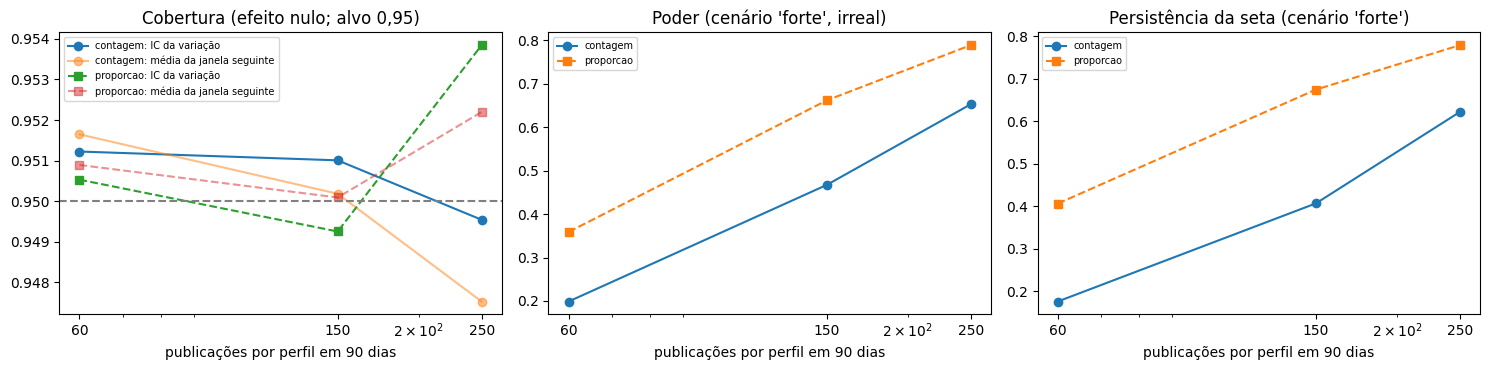

In [9]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 3.8))
for tipo, estilo in [("contagem", "-o"), ("proporcao", "--s")]:
    r = res.loc[(tipo, "base", "nulo")]
    eixos[0].plot(r.index, r["cobertura_ic"], estilo, label=f"{tipo}: IC da variação")
    eixos[0].plot(r.index, r["cobertura_media_janela"], estilo, alpha=0.5, label=f"{tipo}: média da janela seguinte")
    r = res.loc[(tipo, "base", "forte")]
    eixos[1].plot(r.index, r["poder"], estilo, label=tipo)
    eixos[2].plot(r.index, r["persistencia"], estilo, label=tipo)
eixos[0].axhline(0.95, color="gray", ls="--")
eixos[0].set_title("Cobertura (efeito nulo; alvo 0,95)")
eixos[1].set_title("Poder (cenário 'forte', irreal)")
eixos[2].set_title("Persistência da seta (cenário 'forte')")
for ax in eixos:
    ax.set_xlabel("publicações por perfil em 90 dias")
    ax.set_xscale("log")
    ax.set_xticks(N_PUBS)
    ax.set_xticklabels(N_PUBS)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

**O que as tabelas mostram (sintético, 140 repetições por célula; 26 perfis × 3 origens por repetição; linhas correlacionadas, então o erro de Monte Carlo é só indicativo, da ordem de 0,3 a 0,5 pp).**

- **O instrumento recupera a verdade conhecida.** Com efeito nulo e 250 publicações, a cobertura do IC da variação é 95,0% (contagem) e 95,4% (proporção), o falso alarme é 5,0% e 4,6%, e a cobertura da média da janela seguinte é 94,8% e 95,2%. Em todos os cenários de ruído (`viral`, `mix`, `poucos`) o pior caso fica entre 94,7% e 95,4% de cobertura e 4,6% a 5,3% de falso alarme. Isso reproduz o resultado das fases 1 e 2a (OLS com controles e `ols_ref` calibrados) numa janela de 30 dias, e confirma que a lógica de origem móvel não introduz viés.
- **Poder depende do tamanho do efeito e das publicações por janela.** No cenário `forte` (irreal, ±0,5 em log por janela) o poder vai de 20% (60 publicações em 90 dias) a 65% (250) em contagem e de 36% a 79% em proporção; direção errada ≤ 0,1%. No cenário `misto` (realista) o poder é de 3 a 8%: janelas de 30 dias quase nunca enxergam variações de ±15% a ±30% em 90 dias. Persistência da seta no `misto`: 3 a 7%. Ou seja, **com janelas de 30 dias e efeitos realistas, a seta do treino quase nunca se repete na janela seguinte, porque quase nunca existe**.
- **Previsão.** O `ganho_previsao` é muito negativo quando não há tendência (≈ -7 no nulo; -4 a -5 no `misto`): extrapolar a reta estimada em uma janela curta é pior que repetir o nível médio do treino, porque a variância da extrapolação é uma ordem de grandeza maior. Só passa a ser positivo quando o efeito é grande e há muitas publicações (+0,66 em contagem, `forte`, 250). **A Tendência deve ser lida como descrição da janela, não como previsão.** A cobertura dos intervalos de previsão individuais (≈ 95%) mostra que o erro está na incerteza do nível, não na calibração.
- **Tendência não linear (campanha no meio, variação ponta a ponta nula):** 43% de falso alarme nas janelas de 30 dias e cobertura da média da janela seguinte de 35%. O instrumento enxerga o problema (as janelas veem a subida e a queda separadamente), o que é coerente com a ficha: a seta sozinha engana, a série precisa ir junto.
- **Proporção em efeitos enormes:** a proporção muda linear no logit, então a cobertura da média da janela seguinte cai (85% em `alta_geral`, 250 publicações) porque a extrapolação em log deixa de ser linear. É um limite do cenário irreal, e não é avaliada a cobertura do IC nesses perfis (a verdade por janela não é conhecida; ver código).

### 6b. Asserções de sanidade do instrumento

O instrumento só vale se, em dado onde a verdade é conhecida, ele **recuperar o comportamento esperado**. As faixas abaixo foram
fixadas **antes** de ver os números (nominal 95% de cobertura; falso alarme nominal ≤ 5%, folga para o requisito de `MIN_EFEITO` e
erro de Monte Carlo).

In [10]:
def pega(tipo, cen, cen_ef, n):
    return res.loc[(tipo, cen, cen_ef, n)]


verificacoes = []


def checar(nome, cond, valor):
    verificacoes.append({"verificação": nome, "valor": valor, "ok": bool(cond)})
    assert cond, f"FALHOU: {nome} (valor {valor})"


for tipo in ["contagem", "proporcao"]:
    r = pega(tipo, "base", "nulo", 250)
    checar(f"{tipo}: cobertura do IC da variação em [0,92; 0,98] (nulo, base, 250)", 0.92 <= r["cobertura_ic"] <= 0.98, round(r["cobertura_ic"], 3))
    checar(f"{tipo}: falso alarme <= 8% (nulo, base, 250)", r["falso_alarme"] <= 0.08, round(r["falso_alarme"], 3))
    checar(f"{tipo}: cobertura da média da janela seguinte em [0,90; 0,99]", 0.90 <= r["cobertura_media_janela"] <= 0.99, round(r["cobertura_media_janela"], 3))
    r = pega(tipo, "base", "forte", 250)
    checar(f"{tipo}: direção errada <= 2% (forte, 250)", r["direcao_errada"] <= 0.02, round(r["direcao_errada"], 3))
    checar(f"{tipo}: poder >= 50% (forte, 250)", r["poder"] >= 0.50, round(r["poder"], 3))
    checar(f"{tipo}: persistência >= 60% (forte, 250)", r["persistencia"] >= 0.60, round(r["persistencia"], 3))
    checar(f"{tipo}: inversão da seta <= 3% (forte, 250)", r["inversao"] <= 0.03, round(r["inversao"], 3))
    # poder cresce com o nº de publicações
    p60, p250 = pega(tipo, "base", "forte", 60)["poder"], pega(tipo, "base", "forte", 250)["poder"]
    checar(f"{tipo}: poder aumenta de 60 para 250 publicações", p250 > p60, f"{p60:.2f} -> {p250:.2f}")
    # um cenário sem efeito não pode ter mais seta que um cenário forte
    checar(f"{tipo}: nulo tem menos setas que forte", pega(tipo, "base", "nulo", 250)[["subindo", "caindo"]].sum() < pega(tipo, "base", "forte", 250)[["subindo", "caindo"]].sum(), "")

# monotonia dos mínimos: mais exigência => mais 'Dados insuficientes'
sub = sim[(sim.tipo == "contagem") & (sim.cenario == "base") & (sim.cen_ef == "misto") & (sim.n_pubs == 60)]
insuf = [metricas(sub, min_pub=p, min_dias=d)["insuficiente"] for p, d in GRADE_MINIMOS]
checar("insuficiente cresce com os mínimos (10,8) <= (15,12) <= (20,15)", insuf == sorted(insuf) and insuf[-1] > insuf[0], [round(v, 3) for v in insuf])
# MIN_EFEITO maior => menos setas (a seta exige variação maior)
setas = [(lambda m: m["subindo"] + m["caindo"])(metricas(sub, min_efeito=e)) for e in GRADE_MIN_EFEITO]
checar("setas diminuem (ou ficam iguais) com MIN_EFEITO maior", setas == sorted(setas, reverse=True), [round(v, 3) for v in setas])
pd.DataFrame(verificacoes)

,verificação,valor,ok
0,"contagem: cobertura do IC da variação em [0,92...",0.950,True
1,"contagem: falso alarme <= 8% (nulo, base, 250)",0.050,True
2,contagem: cobertura da média da janela seguint...,0.948,True
3,"contagem: direção errada <= 2% (forte, 250)",0.000,True
4,"contagem: poder >= 50% (forte, 250)",0.653,True
5,"contagem: persistência >= 60% (forte, 250)",0.621,True
6,"contagem: inversão da seta <= 3% (forte, 250)",0.001,True
7,contagem: poder aumenta de 60 para 250 publica...,0.20 -> 0.65,True
8,contagem: nulo tem menos setas que forte,,True
9,"proporcao: cobertura do IC da variação em [0,9...",0.954,True


### 6c. Visão "Todos" no *backtest* (mediana das tendências com peso igual por perfil)

Em cada repetição e origem, a tendência do conjunto é a **mediana das tendências individuais** dos perfis com dado suficiente na
janela de treino, IC por *bootstrap* de perfis (precisa de pelo menos 5 perfis suficientes). A verdade do conjunto é a média dos
efeitos verdadeiros (peso igual por perfil). Mede-se acerto do estado, persistência da seta do conjunto entre janelas e inversão.

In [11]:
def todos_por_origem(bt, rng, min_perfis=5, **kw):
    """Uma linha por (repetição, origem): tendência do conjunto no treino e na janela seguinte."""
    min_pub = MIN_PUBLICACOES if kw.get("min_pub") is None else kw["min_pub"]
    min_dias = MIN_DIAS_COM_PUBLICACAO if kw.get("min_dias") is None else kw["min_dias"]
    chaves = [c for c in ["rep", "origem"] if c in bt.columns] or ["origem"]
    linhas = []
    for k, g in bt.groupby(chaves):
        linha = dict(zip(chaves, k if isinstance(k, tuple) else (k,)))
        for suf in ["tr", "te"]:
            ok = g[(g[f"npub_{suf}"] >= min_pub) & (g[f"ndias_{suf}"] >= min_dias) & g[f"est_{suf}"].notna()]
            if len(ok) >= min_perfis:
                est, lo, hi = mediana_boot(ok[f"est_{suf}"].to_numpy(), rng)
                d = pd.DataFrame({"npub": [len(ok)], "ndias": [len(ok)], "est": [est], "lo": [lo], "hi": [hi]})
                d[["npub", "ndias"]] = 10**6
                linha[f"estado_{suf}"] = classificar(d, min_pub=0, min_dias=0, min_efeito=kw.get("min_efeito")).iloc[0]
                linha[f"est_{suf}"] = est
            else:
                linha[f"estado_{suf}"] = "Dados insuficientes"
        if "efeito" in g.columns:
            vl = g.groupby("gov")["verdade_log"].first().mean()
            linha["verdade_log"] = vl
        linhas.append(linha)
    return pd.DataFrame(linhas)


def resumo_todos(td):
    seta = td["estado_tr"].isin(["Subindo", "Caindo"])
    r = {
        "insuficiente": float((td["estado_tr"] == "Dados insuficientes").mean()),
        "subindo": float((td["estado_tr"] == "Subindo").mean()),
        "persistencia": float((td["estado_te"][seta] == td["estado_tr"][seta]).mean()) if seta.any() else np.nan,
        "inversao": float((td["estado_te"][seta] == td["estado_tr"][seta].map(OPOSTO)).mean()) if seta.any() else np.nan,
    }
    return r


rng_td = np.random.default_rng(SEED + 1)
sim_td = sim[(sim.cenario == "base") & (sim.tipo == "contagem")]
linhas_td = {}
for (cen_ef, n), g in sim_td.groupby(["cen_ef", "n_pubs"]):
    td = todos_por_origem(g, rng_td)
    linhas_td[(cen_ef, n)] = resumo_todos(td)
tab_td = pd.DataFrame(linhas_td).T
tab_td.index.names = ["cen_ef", "n_pubs"]
print("Visão 'Todos' (contagem, ruído base). 'subindo' = fração das origens em que o conjunto saiu Subindo:")
tab_td

Visão 'Todos' (contagem, ruído base). 'subindo' = fração das origens em que o conjunto saiu Subindo:


insuficiente  subindo  persistencia  inversao
cen_ef     n_pubs                                               
alta_geral 60             0.000    0.883         0.889     0.000
           150            0.000    1.000         0.995     0.000
           250            0.000    0.998         0.993     0.000
forte      60             0.000    0.048         0.119     0.000
           150            0.000    0.057         0.345     0.000
           250            0.000    0.050         0.257     0.000
misto      60             0.000    0.029         0.036     0.071
           150            0.000    0.026         0.000     0.000
           250            0.000    0.029         0.000     0.000
nulo       60             0.000    0.040         0.000     0.000
           150            0.000    0.031         0.000     0.000
           250            0.000    0.017         0.067     0.067

**Visão "Todos".** Com 80% dos perfis subindo (`alta_geral`, irreal), a mediana das tendências sai Subindo em 88% (60 publicações), 100% (150) e 99,8% (250) das origens, sem nenhuma direção errada e com persistência de 99% da seta entre janelas. Sem efeito (`nulo`), o conjunto sai Subindo/Caindo em 1,7% a 4% das origens e a seta quase nunca se repete, como deveria. No `misto` e no `forte`, em que os efeitos se cancelam, o conjunto fica Estável quase sempre. Isso confirma, no instrumento, a escolha provisória da fase 2a (cada perfil pesa igual) e dá o formato da tabela que a Coleta real vai preencher.

In [12]:
td_alta = todos_por_origem(sim_td[(sim_td.cen_ef == "alta_geral") & (sim_td.n_pubs == 250)], rng_td)
td_nulo = todos_por_origem(sim_td[(sim_td.cen_ef == "nulo") & (sim_td.n_pubs == 250)], rng_td)
a_alta = (td_alta["estado_tr"] == "Subindo").mean()
fa_nulo = td_nulo["estado_tr"].isin(["Subindo", "Caindo"]).mean()
assert a_alta >= 0.90, f"'Todos' deveria sair Subindo quando 80% dos perfis sobem forte (acerto {a_alta:.2f})"
assert fa_nulo <= 0.10, f"'Todos' com falso alarme alto no cenário nulo ({fa_nulo:.2f})"
print(f"Todos: acerto em 'alta_geral' (250 pubs) = {a_alta:.2f}; falso alarme em 'nulo' = {fa_nulo:.2f}  -> OK")

Todos: acerto em 'alta_geral' (250 pubs) = 1.00; falso alarme em 'nulo' = 0.03  -> OK


### 6d. Sensibilidade aos limiares (sintético, cenário `misto`, contagem)

Mesma tabela do *backtest* reclassificada com `MIN_EFEITO` de 2% a 10% e mínimos de publicações/dias de (10, 8) a (20, 15), as
faixas sugeridas no #287. Com a Coleta real, esta é a grade que sustenta a calibração; aqui ela só mostra que o instrumento
responde à mudança de limiares da forma esperada.

In [13]:
def grade_sensibilidade(bt, rng_todos=None):
    linhas = []
    for me in GRADE_MIN_EFEITO:
        for mp, md_ in GRADE_MINIMOS:
            m = metricas(bt, min_pub=mp, min_dias=md_, min_efeito=me)
            linhas.append({"min_efeito": me, "min_pub": mp, "min_dias": md_, **{k: m[k] for k in
                           ["insuficiente", "subindo", "caindo", "estavel", "persistencia", "inversao", "concordancia"] +
                           [x for x in ["falso_alarme", "poder", "direcao_errada"] if x in m]}})
    return pd.DataFrame(linhas)


alvo = sim[(sim.tipo == "contagem") & (sim.cenario == "base") & (sim.cen_ef == "misto") & (sim.n_pubs == 150)]
sens = grade_sensibilidade(alvo)
sens

,min_efeito,min_pub,min_dias,insuficiente,subindo,caindo,estavel,persistencia,inversao,concordancia,falso_alarme,poder,direcao_errada
0,0.020,10,8,0.000,0.026,0.027,0.946,0.036,0.014,0.898,0.049,0.045,0.014
1,0.020,15,12,0.024,0.026,0.026,0.924,0.033,0.012,0.898,0.048,0.044,0.013
2,0.020,20,15,0.210,0.021,0.022,0.747,0.030,0.009,0.898,0.039,0.037,0.011
3,0.050,10,8,0.000,0.026,0.027,0.946,0.036,0.014,0.898,0.049,0.045,0.014
4,0.050,15,12,0.024,0.026,0.026,0.924,0.033,0.012,0.898,0.048,0.044,0.013
5,0.050,20,15,0.210,0.021,0.022,0.747,0.030,0.009,0.898,0.039,0.037,0.011
6,0.100,10,8,0.000,0.026,0.027,0.946,0.036,0.014,0.898,0.049,0.045,0.014
7,0.100,15,12,0.024,0.026,0.026,0.924,0.033,0.012,0.898,0.048,0.044,0.013
8,0.100,20,15,0.210,0.021,0.022,0.747,0.030,0.009,0.898,0.039,0.037,0.011


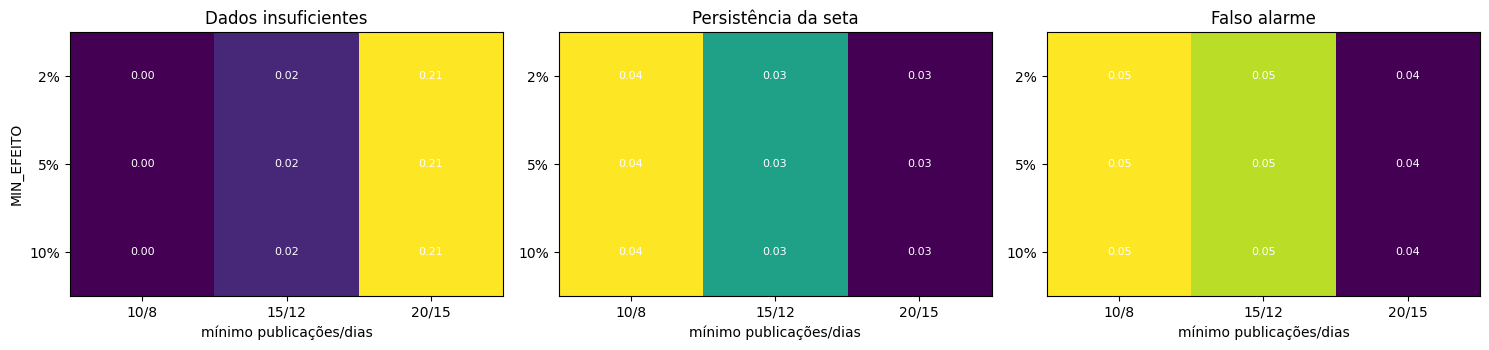

In [14]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col, tit in zip(eixos, ["insuficiente", "persistencia", "falso_alarme"],
                        ["Dados insuficientes", "Persistência da seta", "Falso alarme"]):
    piv = sens.pivot_table(index="min_efeito", columns=sens["min_pub"].astype(str) + "/" + sens["min_dias"].astype(str), values=col)
    im = ax.imshow(piv.values, aspect="auto", cmap="viridis")
    ax.set_xticks(range(piv.shape[1]))
    ax.set_xticklabels(piv.columns)
    ax.set_yticks(range(piv.shape[0]))
    ax.set_yticklabels([f"{v:.0%}" for v in piv.index])
    ax.set_xlabel("mínimo publicações/dias")
    ax.set_title(tit)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            v = piv.values[i, j]
            ax.text(j, i, "n/d" if np.isnan(v) else f"{v:.2f}", ha="center", va="center", color="w", fontsize=8)
eixos[0].set_ylabel("MIN_EFEITO")
plt.tight_layout()
plt.show()

**Sensibilidade (sintético, `misto`, 150 publicações, contagem).** Dois fatos, ambos esperados:

- `MIN_EFEITO` de 2% a 10% **não muda nada** (linhas idênticas): quando o IC de 95% exclui zero a variação estimada já passa de 10%. O mesmo resultado da fase 2a; a decisão sobre `MIN_EFEITO` precisa vir de critério de produto, não de estatística, ou de um dado real em que variações pequenas sejam estimadas com precisão.
- Os mínimos mexem em quantos perfis ficam sem seta: "Dados insuficientes" é 0% com (10, 8), 2,4% com (15, 12) e 21% com (20, 15), enquanto o falso alarme cai de 4,9% para 3,9% e o poder de 4,5% para 3,7% (as setas diminuem juntas). O custo de subir os mínimos é perder perfis; o ganho em falso alarme é pequeno porque já está no nominal.

Nesta grade a diferença entre as linhas é pequena porque o gerador publica ~50 vezes por janela; com a Coleta real, em que o número de dias distintos por janela é a restrição, essa tabela é a que decide.

## 7. Conferência das premissas do gerador contra o dado

O gerador assume: (i) ruído **log-normal** (resíduos do log aproximadamente normais, sem cauda pesada); (ii) publicação em
**rajadas** (variância das contagens diárias maior que a de Poisson, `Fano > 1`); (iii) tendência **linear** no log (o termo
quadrático não deve ser significativo além do nível nominal de 5%); (iv) em proporção, **sobredispersão** além da binomial.

As funções abaixo medem isso em qualquer lista de séries (uma por perfil). Antes de olhar o dado real elas são **validadas no
próprio gerador**, onde as premissas são verdadeiras (devem dar "tudo conforme") e numa série com campanha (o quadrático deve
acusar). Na Coleta real, rodam sobre a série do recorte.

In [15]:
def diag_residuos(dfs, tipo, min_pubs=12):
    """Normalidade dos resíduos e linearidade (termo quadrático) do OLS com controle de formato, por perfil."""
    zs, sh, quad, sig = [], [], [], []
    for df in dfs:
        if len(df) < min_pubs:
            continue
        t = df["t"].to_numpy(float)
        f = df["formato"].to_numpy(float)
        usa = np.unique(f).size > 1
        try:
            X = montar_X(t, f, usa)
            z = resposta(df, tipo)
            _, _, _, s2, res = ols(z, X)
            tc = t - t.mean()
            b2, c2, gl2, _, _ = ols(z, np.column_stack([X, tc**2]))
        except np.linalg.LinAlgError:
            continue
        zs.append(res / np.sqrt(s2))
        sig.append(np.sqrt(s2))
        sh.append(stats.shapiro(res).pvalue)
        quad.append(2 * stats.t.sf(abs(b2[-1] / np.sqrt(c2[-1, -1])), gl2))
    if not zs:
        return {"perfis": 0}, np.array([])
    z_all = np.concatenate(zs)
    return {
        "perfis": len(zs),
        "sigma_residual_mediano": float(np.median(sig)),
        "assimetria_residuos": float(stats.skew(z_all)),
        "curtose_excesso": float(stats.kurtosis(z_all)),
        "perfis_que_rejeitam_normalidade": float(np.mean(np.array(sh) < 0.05)),
        "perfis_com_quadratico_signif": float(np.mean(np.array(quad) < 0.05)),
    }, z_all


def diag_rajadas(dfs, min_dias=4):
    """Publicação em rajadas: CV dos intervalos entre dias com publicação e Fano das contagens diárias (Poisson = 1)."""
    cvs, fanos, ocup = [], [], []
    for df in dfs:
        d = np.sort(df["dia"].unique())
        if len(d) < min_dias:
            continue
        gaps = np.diff(d)
        cvs.append(gaps.std() / gaps.mean())
        cont = df.groupby("dia").size().reindex(np.arange(d.min(), d.max() + 1), fill_value=0)
        fanos.append(cont.var() / cont.mean())
        ocup.append(len(d) / (d.max() - d.min() + 1))
    if not cvs:
        return {"perfis_rajadas": 0}
    return {"perfis_rajadas": len(cvs), "fano_mediano": float(np.median(fanos)), "cv_intervalos_mediano": float(np.median(cvs)),
            "fracao_dias_com_publicacao": float(np.median(ocup))}


def diag_sobredispersao(dfs, min_pubs=12):
    """Proporção: Pearson/gl de uma binomial com p único por perfil (1 = binomial pura; > 1 = sobredispersão)."""
    phis, zeros, nmed = [], [], []
    for df in dfs:
        df = df[df["n"] >= 1]
        if len(df) < min_pubs:
            continue
        p = df["k"].sum() / df["n"].sum()
        if not 0 < p < 1:
            continue
        phis.append(float(np.sum((df["k"] - df["n"] * p) ** 2 / (df["n"] * p * (1 - p))) / (len(df) - 1)))
        zeros.append(float((df["k"] == 0).mean()))
        nmed.append(float(df["n"].median()))
    if not phis:
        return {"perfis_prop": 0}
    return {"perfis_prop": len(phis), "dispersao_pearson_mediana": float(np.median(phis)),
            "fracao_posts_k0": float(np.mean(zeros)), "comentarios_por_post_mediano": float(np.median(nmed))}


def diagnosticar(dfs, tipo):
    r, z = diag_residuos(dfs, tipo)
    r.update(diag_rajadas(dfs))
    if tipo == "proporcao":
        r.update(diag_sobredispersao(dfs))
    return r, z


rng_dg = np.random.default_rng(SEED + 5)
dfs_base = [gerar_perfil(rng_dg, 150, 0.3 * rng_dg.choice([-1, 0, 1]), "base") for _ in range(200)]
dfs_puro = [gerar_perfil(rng_dg, 150, 0.3 * rng_dg.choice([-1, 0, 1]), "puro") for _ in range(200)]
dfs_camp = [gerar_perfil(rng_dg, 150, 0.0, "base", campanha_meio) for _ in range(200)]
dfs_prop = [gerar_perfil_prop(rng_dg, 150, 0.3 * rng_dg.choice([-1, 0, 1]), "base") for _ in range(200)]
dg_base, z_base = diagnosticar(dfs_base, "contagem")
dg_puro, _ = diagnosticar(dfs_puro, "contagem")
dg_camp, _ = diagnosticar(dfs_camp, "contagem")
dg_prop, _ = diagnosticar(dfs_prop, "proporcao")
val = pd.DataFrame({"gerador log-normal pura": dg_puro, "gerador 'base' (contagem)": dg_base, "gerador com campanha": dg_camp, "gerador 'base' (proporção)": dg_prop})
print("Validação dos diagnósticos no próprio gerador (200 perfis de 150 publicações):")
val

Validação dos diagnósticos no próprio gerador (200 perfis de 150 publicações):


,gerador log-normal pura,gerador 'base' (contagem),gerador com campanha,gerador 'base' (proporção)
perfis,200.000,200.000,200.000,200.000
sigma_residual_mediano,0.497,0.524,0.587,0.411
assimetria_residuos,0.005,0.237,0.267,-0.896
curtose_excesso,-0.052,0.579,0.319,1.912
perfis_que_rejeitam_normalidade,0.045,0.280,0.245,0.860
perfis_com_quadratico_signif,0.070,0.060,0.990,0.035
perfis_rajadas,200.000,200.000,200.000,200.000
fano_mediano,3.450,3.673,3.498,3.541
cv_intervalos_mediano,0.638,0.646,0.639,0.625
fracao_dias_com_publicacao,0.569,0.557,0.557,0.563


In [16]:
# O diagnóstico precisa acusar o que sabemos que é verdade no gerador:
assert abs(dg_base["sigma_residual_mediano"] - 0.5) < 0.04, dg_base["sigma_residual_mediano"]        # sigma do gerador = 0,5
assert dg_base["perfis_com_quadratico_signif"] <= 0.12, dg_base["perfis_com_quadratico_signif"]      # linear => ~5%
assert dg_camp["perfis_com_quadratico_signif"] >= 0.30, dg_camp["perfis_com_quadratico_signif"]      # campanha => acusa
# normalidade: o teste não rejeita a log-normal pura (~5%), mas acusa a contaminação por posts virais do cenário 'base'
# (a faixa inicial, <= 20% no 'base', foi fixada antes de ver o número e estava errada: o 'base' tem 1% de posts x5)
assert dg_puro["perfis_que_rejeitam_normalidade"] <= 0.12, dg_puro["perfis_que_rejeitam_normalidade"]
assert dg_base["perfis_que_rejeitam_normalidade"] > dg_puro["perfis_que_rejeitam_normalidade"] + 0.05
assert dg_base["fano_mediano"] > 1.0, dg_base["fano_mediano"]                                          # gerador publica em rajadas
assert dg_prop["dispersao_pearson_mediana"] > 1.5, dg_prop["dispersao_pearson_mediana"]               # sobredispersão do gerador
print("Diagnósticos validados no gerador: sigma recuperado, linear não acusa, campanha acusa, rajadas e sobredispersão detectadas.")

Diagnósticos validados no gerador: sigma recuperado, linear não acusa, campanha acusa, rajadas e sobredispersão detectadas.


**Validação dos diagnósticos no gerador (200 perfis × 150 publicações).** Onde as premissas são verdadeiras, o diagnóstico dá o que se espera: na log-normal pura, `sigma` residual 0,497 (verdade 0,5), assimetria ≈ 0, excesso de curtose ≈ 0, 4,5% dos perfis rejeitam normalidade (nominal 5%) e 7% têm termo quadrático significativo. O cenário `base` do gerador (1% de posts virais ×5) já derruba a normalidade (28% de rejeição, curtose 0,6): o instrumento detecta a contaminação por outliers que o próprio gerador tem. Na série com campanha o quadrático é significativo em 99% dos perfis (contra 6% a 7% quando é linear). O Fano das contagens diárias (≈ 3,5 a 3,7, contra 1 de Poisson) mostra o regime de rajadas que o gerador impõe, e a sobredispersão de Pearson da proporção é 4,2 (binomial pura = 1). As asserções da célula anterior fixam isso; uma delas (normalidade em `base`) tinha faixa inicial errada e foi corrigida para comparar contra a log-normal pura (registrado no código).

## 8. Carga das séries brutas de uma Coleta (Silver/Gold, somente leitura)

Funções de carga, parametrizadas por `COLETA_DIR` (seção 2). Tabelas e colunas reais, conferidas na Silver/Gold do piloto:

| Série | Fonte | Unidade | Colunas usadas |
|---|---|---|---|
| Valor (contagem) | `silver/reels_clean` + `silver/posts_clean` | uma linha por reel/post | `id`, `ownerUsername` (governador), `data_hora`, `Total de Engajamento` (reel) ou `likesCount + commentsCount` (post); formato = `REELS`/`FEED` |
| Proporção | `gold/governor_sentiment` (linhas `fonte == "comentario"`) | uma linha por comentário | `id_reel` (id do reel **ou** do post, desambiguado por `origem_comentario`), `sentiment_label` |

A proporção por publicação é `k` = comentários `positive` e `n` = comentários com rótulo de sentimento, ligada à data de
publicação pela tabela de reels/posts. O governador é sempre o dono da **publicação** (nas linhas de comentário,
`ownerUsername` é quem comentou). A data de publicação (`data_hora`) vira o dia do recorte.

In [17]:
def _ler_delta(caminho):
    from deltalake import DeltaTable

    return DeltaTable(str(caminho)).to_pandas()


def carregar_publicacoes(coleta_dir):
    """Reels e posts da Silver, uma linha por publicação: id, origem, perfil, data, formato, valor."""
    silver = Path(coleta_dir) / "silver"
    r = _ler_delta(silver / "reels_clean")
    p = _ler_delta(silver / "posts_clean")
    reels = pd.DataFrame({"id": r["id"], "origem": "reel", "perfil": r["ownerUsername"], "data": pd.to_datetime(r["data_hora"]),
                          "formato": 1, "valor": r["Total de Engajamento"].astype(float)})
    posts = pd.DataFrame({"id": p["id"], "origem": "post", "perfil": p["ownerUsername"], "data": pd.to_datetime(p["data_hora"]),
                          "formato": 0, "valor": (p["likesCount"].clip(lower=0) + p["commentsCount"].clip(lower=0)).astype(float)})
    return pd.concat([reels, posts], ignore_index=True).dropna(subset=["data", "perfil"])


def carregar_comentarios_sentimento(coleta_dir):
    """k (positivos) e n (rotulados) por publicação, da Gold governor_sentiment. DataFrame vazio se a Gold não existir."""
    gold = Path(coleta_dir) / "gold" / "governor_sentiment"
    if not gold.exists():
        return pd.DataFrame(columns=["id", "origem", "k", "n"])
    s = _ler_delta(gold)
    s = s[(s["fonte"] == "comentario") & s["sentiment_label"].notna()]
    g = s.groupby(["origem_comentario", "id_reel"]).agg(k=("sentiment_label", lambda x: int((x == "positive").sum())),
                                                          n=("sentiment_label", "size")).reset_index()
    return g.rename(columns={"origem_comentario": "origem", "id_reel": "id"})


def aplicar_recorte(pubs, recorte_dias):
    """Dia inteiro desde o início do recorte (últimos `recorte_dias` dias de publicação, ou todo o histórico se None)."""
    dia_pub = pubs["data"].dt.normalize()
    fim = dia_pub.max()
    inicio = dia_pub.min() if recorte_dias is None else fim - pd.Timedelta(days=recorte_dias - 1)
    out = pubs.assign(dia=(dia_pub - inicio).dt.days)
    total = int(out["dia"].max()) + 1 if recorte_dias is None else int(recorte_dias)
    return out[(out["dia"] >= 0) & (out["dia"] < total)].copy(), total


def carregar_series(coleta_dir, recorte_dias):
    """Devolve (series_valor, series_prop, total_dias, meta). series_*: dict perfil -> DataFrame(dia, t, formato, y | n, k)."""
    pubs, total = aplicar_recorte(carregar_publicacoes(coleta_dir), recorte_dias)
    pubs["t"] = pubs["dia"] / total
    valor = {pf: g[["dia", "t", "formato"]].assign(y=g["valor"].clip(lower=1)).reset_index(drop=True) for pf, g in pubs.groupby("perfil")}
    com = carregar_comentarios_sentimento(coleta_dir)
    prop = {}
    if len(com):
        pp = pubs.merge(com, on=["origem", "id"], how="inner")
        prop = {pf: g[["dia", "t", "formato", "n", "k"]].reset_index(drop=True) for pf, g in pp.groupby("perfil")}
    meta = {"publicacoes": len(pubs), "perfis": pubs["perfil"].nunique(), "dias_recorte": total,
            "primeira": pubs["data"].min(), "ultima": pubs["data"].max(),
            "pubs_com_comentario_rotulado": int(sum(len(v) for v in prop.values()))}
    return valor, prop, total, meta


COLETA_OK = (Path(COLETA_DIR) / "silver" / "reels_clean").exists() and (Path(COLETA_DIR) / "silver" / "posts_clean").exists()
if not COLETA_OK:
    print(f"ATENÇÃO: Silver não encontrada em {COLETA_DIR!r}. As seções com dado real serão puladas; a validação sintética segue valendo.")
else:
    _v, _p, _tot, meta = carregar_series(COLETA_DIR, RECORTE_DIAS)
    print("Coleta carregada (somente leitura):", COLETA_DIR)
    print(meta)
    print("Publicações por perfil (recorte):", pd.Series({k: len(v) for k, v in _v.items()}).describe().round(1).to_dict())

Coleta carregada (somente leitura): C:\Projetos\Tecnicas-de-NLP-em-dados-do-Instagram\data
{'publicacoes': 909, 'perfis': 25, 'dias_recorte': 90, 'primeira': Timestamp('2026-07-09 18:03:47'), 'ultima': Timestamp('2026-10-06 13:54:42'), 'pubs_com_comentario_rotulado': 632}
Publicações por perfil (recorte): {'count': 25.0, 'mean': 36.4, 'std': 16.8, 'min': 1.0, '25%': 27.0, '50%': 38.0, '75%': 48.0, 'max': 60.0}


## 9. Teste de fumaça com a Silver do piloto (NÃO é avaliação)

> **Aviso explícito.** O piloto tem poucos dias distintos de publicação por perfil: o teto de 30 itens por perfil foi coletado
> em um único dia (outubro de 2026) e o histórico dos reels vai a janeiro de 2025. Na avaliação anterior, **24 de 25 perfis ficaram
> "Dados insuficientes"**. Esta seção só confirma que o carregamento e o *backtest* **rodam** nas colunas reais e produzem as
> mesmas tabelas que a Coleta produzirá. **Nada aqui permite concluir qualquer coisa sobre método, limiares ou premissas.**

Duas configurações: (a) o recorte de 90 dias com janelas de 30 dias (o desenho da Coleta); (b) todo o histórico com janelas de
180 dias, só para exercitar o código com mais publicações por janela.

In [18]:
CONFIGS_FUMACA = [("recorte 90d, janelas 30d", 90, 30, 15), ("histórico completo, janelas 180d", None, 180, 90)]
fumaca = {}
if COLETA_OK:
    linhas_f = []
    for nome, rec, W, passo in CONFIGS_FUMACA:
        v, p, tot, meta_f = carregar_series(COLETA_DIR, rec)
        for tipo, series in [("contagem", v), ("proporcao", p)]:
            if not series:
                linhas_f.append({"configuração": nome, "tipo": tipo, "observação": "sem série (Gold ausente?)"})
                continue
            bt = backtest_coleta(series, tipo, tot, W, passo)
            fumaca[(nome, tipo)] = bt
            if bt.empty:
                linhas_f.append({"configuração": nome, "tipo": tipo, "observação": f"recorte de {tot} dias não comporta 2 janelas de {W}"})
                continue
            m = metricas(bt)
            dist = distribuicao_ultima_janela(bt)
            ult = bt[bt["origem"] == bt["origem"].max()]
            linhas_f.append({"configuração": nome, "tipo": tipo, "perfis": bt["perfil"].nunique(), "origens": bt["origem"].nunique(),
                             "pubs na última janela (mediana)": ult["npub_te"].median(), "dias distintos na última janela (mediana)": ult["ndias_te"].median(),
                             "insuficiente (treino)": m["insuficiente"], "última janela: Subindo": dist["Subindo"],
                             "Caindo": dist["Caindo"], "Estável": dist["Estável"], "Dados insuficientes": dist["Dados insuficientes"],
                             "cobertura média janela": m["cobertura_media_janela"], "persistência": m["persistencia"]})
    tab_fumaca = pd.DataFrame(linhas_f)
    print("Teste de fumaça (piloto): código roda; leia como 'o que o contrato daria hoje', não como resultado.")
    display_tab = tab_fumaca
else:
    display_tab = pd.DataFrame({"observação": ["Silver do piloto não encontrada; fumaça pulada."]})
display_tab

Teste de fumaça (piloto): código roda; leia como 'o que o contrato daria hoje', não como resultado.


,configuração,tipo,perfis,origens,pubs na última janela (mediana),dias distintos na última janela (mediana),insuficiente (treino),última janela: Subindo,Caindo,Estável,Dados insuficientes,cobertura média janela,persistência
0,"recorte 90d, janelas 30d",contagem,25,3,36.000,5.000,1.000,0,0,1,24,NaN,NaN
1,"recorte 90d, janelas 30d",proporcao,25,3,26.000,5.000,1.000,0,0,1,24,NaN,NaN
2,"histórico completo, janelas 180d",contagem,26,4,0.000,0.000,1.000,0,0,0,26,NaN,NaN
3,"histórico completo, janelas 180d",proporcao,26,4,0.000,0.000,1.000,0,0,0,26,NaN,NaN


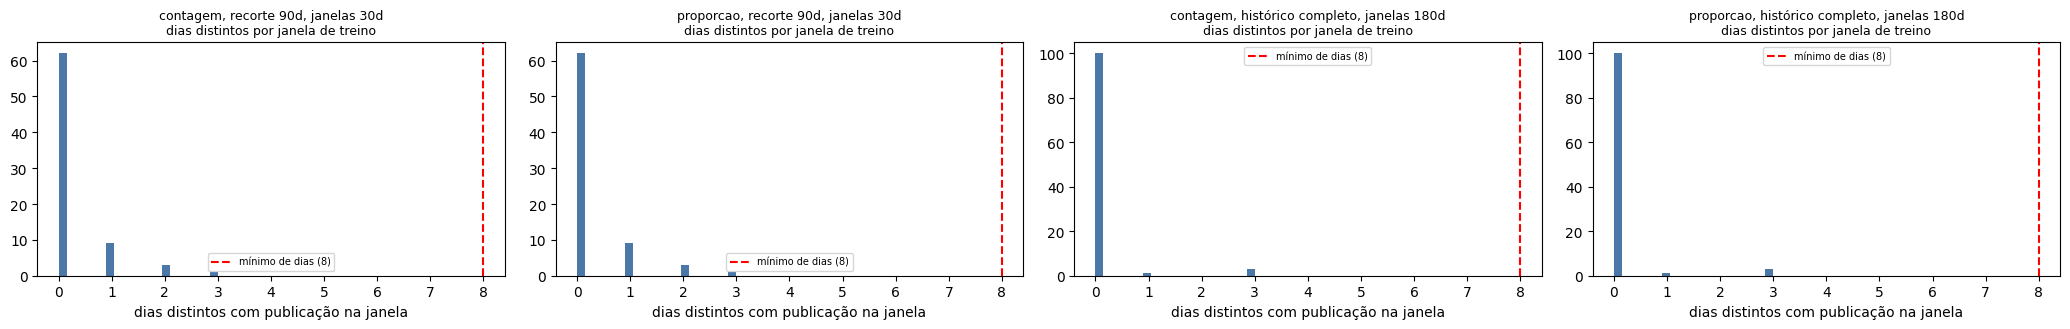

In [19]:
if COLETA_OK and fumaca:
    fig, eixos = plt.subplots(1, len(fumaca), figsize=(5.2 * len(fumaca), 3.4), squeeze=False)
    for ax, ((nome, tipo), bt) in zip(eixos[0], fumaca.items()):
        if bt.empty:
            ax.axis("off")
            continue
        ax.hist(bt["ndias_tr"], bins=20, color="#4c78a8")
        ax.axvline(MIN_DIAS_COM_PUBLICACAO, color="red", ls="--", label=f"mínimo de dias ({MIN_DIAS_COM_PUBLICACAO})")
        ax.set_title(f"{tipo}, {nome}\ndias distintos por janela de treino", fontsize=9)
        ax.set_xlabel("dias distintos com publicação na janela")
        ax.legend(fontsize=7)
    plt.tight_layout()
    plt.show()

**Resultado do teste de fumaça (piloto), só como conferência de que o código roda.**

- Carregou 909 publicações (reels + posts) de 25 perfis no recorte de 90 dias (9 jul a 6 out de 2026) e 632 publicações com comentário rotulado para a proporção. O *backtest* rodou nas duas séries, nas duas configurações.
- **24 de 25 perfis ficam "Dados insuficientes" na janela mais recente nos dois indicadores** (mesmo resultado da avaliação anterior), e 1 perfil fica Estável. A causa aparece na tabela: a mediana é de 36 publicações na última janela de 30 dias mas de apenas **5 dias distintos** (mínimo 8), porque o piloto foi extraído por teto de itens e as publicações se concentram em poucos dias. Na configuração de histórico completo (janelas de 180 dias) as janelas centrais estão praticamente vazias.
- Sem seta nenhuma, as métricas de persistência e de cobertura ficam indefinidas (NaN): o *backtest* de verdade só existe com a Coleta.

**Nada disso fala sobre método, limiares ou premissas.**

## 10. Premissas do gerador contra o dado do piloto (também só fumaça)

Os mesmos diagnósticos da seção 7, sobre o histórico completo do piloto (sem recorte, para ter mais pontos por perfil). Em
aviso explícito: são poucos perfis com 12 ou mais publicações e a amostra do piloto foi coletada por teto de itens, não por
janela de tempo, então o quadro **não** representa a Coleta de 90 dias. O objetivo é exercitar o diagnóstico e as figuras.

In [20]:
if COLETA_OK:
    v_full, p_full, tot_full, _ = carregar_series(COLETA_DIR, None)
    dg_v, z_v = diagnosticar(list(v_full.values()), "contagem")
    dg_p, _ = diagnosticar(list(p_full.values()), "proporcao") if p_full else ({}, np.array([]))
    comp = pd.DataFrame({"gerador 'base' (contagem)": dg_base, "piloto (contagem)": dg_v, "gerador 'base' (proporção)": dg_prop,
                         "piloto (proporção)": dg_p})
    print(f"Piloto: {len(v_full)} perfis, histórico de {tot_full} dias. Diagnósticos lado a lado com o gerador:")
    display_diag = comp
else:
    display_diag = pd.DataFrame({"observação": ["Silver do piloto não encontrada."]})
display_diag

Piloto: 26 perfis, histórico de 639 dias. Diagnósticos lado a lado com o gerador:


,gerador 'base' (contagem),piloto (contagem),gerador 'base' (proporção),piloto (proporção)
perfis,200.000,23.000,200.000,22.000
sigma_residual_mediano,0.524,1.036,0.411,0.503
assimetria_residuos,0.237,0.155,-0.896,-1.692
curtose_excesso,0.579,-0.436,1.912,4.826
perfis_que_rejeitam_normalidade,0.280,0.174,0.860,0.636
perfis_com_quadratico_signif,0.060,0.304,0.035,0.091
perfis_rajadas,200.000,24.000,200.000,24.000
fano_mediano,3.673,7.329,3.541,3.898
cv_intervalos_mediano,0.646,0.651,0.625,0.651
fracao_dias_com_publicacao,0.557,0.650,0.563,0.650


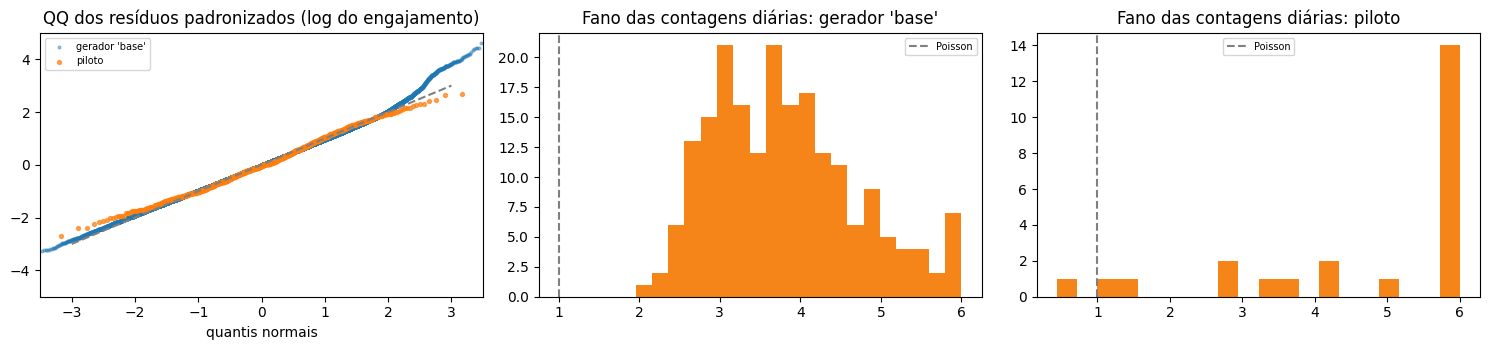

In [21]:
if COLETA_OK and len(z_v) > 10:
    fig, eixos = plt.subplots(1, 3, figsize=(15, 3.6))
    (x1, y1), _ = stats.probplot(z_base, dist="norm")[:2]
    (x2, y2), _ = stats.probplot(z_v, dist="norm")[:2]
    eixos[0].scatter(x1, y1, s=4, alpha=0.4, label="gerador 'base'")
    eixos[0].scatter(x2, y2, s=8, alpha=0.7, label="piloto")
    eixos[0].plot([-3, 3], [-3, 3], color="gray", ls="--")
    eixos[0].set_xlim(-3.5, 3.5)
    eixos[0].set_ylim(-5, 5)
    eixos[0].set_title("QQ dos resíduos padronizados (log do engajamento)")
    eixos[0].set_xlabel("quantis normais")
    eixos[0].legend(fontsize=7)
    for ax, (nome, serie) in zip(eixos[1:], [("gerador 'base'", dfs_base), ("piloto", list(v_full.values()))]):
        fanos = []
        for df in serie:
            d = np.sort(df["dia"].unique())
            if len(d) >= 4:
                cont = df.groupby("dia").size().reindex(np.arange(d.min(), d.max() + 1), fill_value=0)
                fanos.append(cont.var() / cont.mean())
        ax.hist(np.clip(fanos, 0, 6), bins=20, color="#f58518")
        ax.axvline(1, color="gray", ls="--", label="Poisson")
        ax.set_title(f"Fano das contagens diárias: {nome}")
        ax.legend(fontsize=7)
    plt.tight_layout()
    plt.show()

**Premissas contra o piloto (somente fumaça; 23 perfis de contagem e 22 de proporção com 12 ou mais publicações, histórico completo).** Observações, sem concluir:

- Resíduo do log do engajamento: `sigma` mediano 1,04 (o gerador usa 0,5), então o ruído do piloto é muito maior que o do gerador; assimetria 0,16 e curtose -0,44 (caudas leves, sem evidência de log-normal contaminada de virais); 17% dos perfis rejeitam normalidade.
- Linearidade: 30% dos perfis têm termo quadrático significativo, contra 6% a 7% esperados se fosse linear. Isso é compatível com a ficha (campanha, sazonalidade) mas o piloto cobre 21 meses com poucas publicações por perfil, o que sozinho produz curvatura.
- Rajadas: Fano mediano 7,3 (gerador 3,5), isto é, mais agrupado ainda que o gerador (o piloto concentra muitas publicações em poucos dias).
- Proporção: sobredispersão de Pearson mediana 2,4 (gerador 4,2) com mediana de 14 comentários por publicação (gerador ~40): a sobredispersão existe, em grau menor que o do gerador.

O que isso sugere para a Coleta real (a conferir): ruído maior que o do gerador, mais rajadas e possível curvatura. Nenhum desses pontos foi testado em dado representativo.

## 11. Como executar com a Coleta de 90 dias (passo a passo)

> Nada disto foi feito neste notebook. Cada passo depende de decisão e aval do autor.

**Antes de rodar**

1. A Coleta de 90 dias (#256) precisa existir, **extraída pelo autor com `--yes` e aprovação explícita de custo**
   (`docs/agents/coletas.md`). Este notebook e o #284 não executam extração e nunca apagam uma Coleta anterior.
2. Deixe a Silver e a Gold da Coleta numa pasta local com `silver/` e `gold/` (por exemplo, restaurada ou baixada do Hugging Face
   com `coleta.py`, em pasta **separada** de `data/` em uso; veja `docs/agents/coletas.md` para os comandos e confirme as opções
   com `--help`). A Gold precisa ter `governor_sentiment`.

**Parâmetros a trocar (seção 2, célula de parâmetros)**

3. `COLETA_DIR` -> a pasta da Coleta (único parâmetro obrigatório).
4. Conferir `RECORTE_DIAS = 90`, `JANELA_DIAS = 30` e `PASSO_DIAS = 15`. Se a Coleta tiver mais de 90 dias de publicações,
   decidir o recorte; para janelas mais longas, ajustar `JANELA_DIAS` (o instrumento exige que caibam duas janelas no recorte).
5. Conferir a grade `GRADE_MIN_EFEITO` e `GRADE_MINIMOS` (faixas sugeridas no #287: `MIN_EFEITO` 2 a 10%, publicações 10 a 20,
   dias distintos 8 a 15) e, se quiser mais precisão sintética, `REPS_BT` e `N_PUBS`.
6. Executar de ponta a ponta: `jupyter nbconvert --to notebook --execute --inplace notebooks/modelagens/tendencia_03_backtest.ipynb`
   (cerca de 10 minutos). Nenhuma asserção deve falhar; se a de sanidade sintética falhar, o instrumento tem defeito e nenhum
   resultado real deve ser lido.

**O que olhar no resultado real** (as seções 9 e 10 passam a ser a avaliação, não a fumaça; reescreva os avisos)

7. Distribuição de estados na janela mais recente, por tipo de indicador e por limiar: quantos governadores ficam
   "Dados insuficientes" com cada par de mínimos.
8. Persistência e inversão da seta entre janelas, concordância, cobertura da média da janela seguinte e ganho de previsão
   (tendência contra "só nível"). Comparar com o sintético: se o real for muito pior que o sintético, as premissas do gerador
   não valem.
9. Premissas (seção 10): resíduos do log aproximadamente normais, rajadas, quadrático e sobredispersão. Reler os "limites" da
   ficha à luz disso.
10. Visão "Todos": rodar `todos_por_origem` sobre o `backtest_coleta` real e conferir a persistência da seta do conjunto.

**O que decidir e preencher manualmente (fora deste notebook)**

11. Método final por tipo de indicador (contagem e proporção) e a regra de "Todos", com a evidência registrada aqui.
12. Limiares finais: `MIN_EFEITO`, `MIN_PUBLICACOES`, `MIN_DIAS_COM_PUBLICACAO`.
13. Atualizar `docs/modelagens/tendencia.md` (status `validada` ou `descartada`), marcar o ADR 0040 como `accepted` com o método
    e os limiares finais, ajustar `CONTEXT.md`, e aplicar `ready-for-agent` ao issue de implementação no dashboard.
14. Fechar o #284 só depois de tudo acima e da aprovação do autor.

In [22]:
print(f"Tempo total de execução: {(time.time() - T0) / 60:.1f} min")

Tempo total de execução: 7.5 min
